# 🌍 Air Quality Forecasting Using Time Series Analysis

## 📌 Notebook 01 — Data Understanding

### 1. Project Overview

Air pollution is one of the major environmental challenges affecting human health and quality of life. The **Air Quality Index (AQI)** provides a simplified way of representing the overall level of air pollution based on different pollutants present in the atmosphere.

In this project, we will build an **end-to-end Air Quality Forecasting system** using historical air-quality data. The main objective is to understand historical AQI patterns and eventually forecast future AQI values using different **time series, machine learning, and deep learning techniques**.

The project will start with understanding and preparing the data before moving toward forecasting models.

---

## 🎯 2. Project Objective

The primary objective of this project is:

> **To analyze historical air-quality patterns and develop models capable of forecasting future AQI values for a selected location.**

We will begin with **daily city-level air-quality data** and gradually progress from traditional statistical forecasting techniques to machine learning and deep learning approaches.

The final objective is to identify a forecasting model that provides reliable predictions while also understanding **why and how the model works**.

---

## 📂 3. Dataset Overview

The project contains air-quality data at both **city level** and **station level**, with daily and hourly observations.

The available datasets are:

| Dataset | Description |
|---|---|
| `city_day.csv` | Daily air-quality measurements at city level |
| `city_hour.csv` | Hourly air-quality measurements at city level |
| `station_day.csv` | Daily air-quality measurements at monitoring-station level |
| `station_hour.csv` | Hourly air-quality measurements at monitoring-station level |
| `stations.csv` | Monitoring-station metadata |

The datasets contain measurements for several pollutants, including:

- PM2.5
- PM10
- NO
- NO₂
- NOx
- NH₃
- CO
- SO₂
- O₃
- Benzene
- Toluene
- Xylene

The dataset also contains:

- **AQI** — Air Quality Index
- **AQI_Bucket** — Corresponding AQI category

---

## 🔎 4. Forecasting Problem

The initial forecasting problem will focus on:

> **Forecasting future daily AQI values using historical AQI observations for a selected city.**

Conceptually:

```text
Historical AQI
      ↓
Data Preparation
      ↓
Exploratory Time Series Analysis
      ↓
Trend & Seasonality
      ↓
Statistical / ML / DL Models
      ↓
Future AQI Forecast

In [1]:
import sys

print(sys.version)

3.14.5 (main, May 10 2026, 10:21:34) [Clang 21.0.0 (clang-2100.0.123.102)]


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
df = pd.read_csv("../data/raw/city_day.csv")

In [4]:
df.head()

,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN


In [5]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 29531
Columns: 16


## 3. Understanding the Dataset Structure

Before performing any preprocessing or forecasting, we first need to understand what each column represents, identify the data types, and examine the overall structure of the dataset.

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 29531 entries, 0 to 29530
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   City        29531 non-null  str    
 1   Date        29531 non-null  str    
 2   PM2.5       24933 non-null  float64
 3   PM10        18391 non-null  float64
 4   NO          25949 non-null  float64
 5   NO2         25946 non-null  float64
 6   NOx         25346 non-null  float64
 7   NH3         19203 non-null  float64
 8   CO          27472 non-null  float64
 9   SO2         25677 non-null  float64
 10  O3          25509 non-null  float64
 11  Benzene     23908 non-null  float64
 12  Toluene     21490 non-null  float64
 13  Xylene      11422 non-null  float64
 14  AQI         24850 non-null  float64
 15  AQI_Bucket  24850 non-null  str    
dtypes: float64(13), str(3)
memory usage: 3.6 MB


## 4. Dataset Columns

Let's examine all the variables available in the dataset and understand which variables represent pollutants, the target variable, and supporting information.

In [7]:
df.columns.tolist()

['City',
 'Date',
 'PM2.5',
 'PM10',
 'NO',
 'NO2',
 'NOx',
 'NH3',
 'CO',
 'SO2',
 'O3',
 'Benzene',
 'Toluene',
 'Xylene',
 'AQI',
 'AQI_Bucket']

In [8]:
df.dtypes

City              str
Date              str
PM2.5         float64
PM10          float64
NO            float64
NO2           float64
NOx           float64
NH3           float64
CO            float64
SO2           float64
O3            float64
Benzene       float64
Toluene       float64
Xylene        float64
AQI           float64
AQI_Bucket        str
dtype: object

## 5. Statistical Summary

Let's examine the numerical variables using descriptive statistics such as count, mean, standard deviation, minimum, maximum, and quartiles.

In [9]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
PM2.5,24933.0,67.450578,64.661449,0.04,28.820,48.57,80.5900,949.99
PM10,18391.0,118.127103,90.605110,0.01,56.255,95.68,149.7450,1000.00
NO,25949.0,17.574730,22.785846,0.02,5.630,9.89,19.9500,390.68
NO2,25946.0,28.560659,24.474746,0.01,11.750,21.69,37.6200,362.21
NOx,25346.0,32.309123,31.646011,0.00,12.820,23.52,40.1275,467.63
NH3,19203.0,23.483476,25.684275,0.01,8.580,15.85,30.0200,352.89
CO,27472.0,2.248598,6.962884,0.00,0.510,0.89,1.4500,175.81
SO2,25677.0,14.531977,18.133775,0.01,5.670,9.16,15.2200,193.86
O3,25509.0,34.491430,21.694928,0.01,18.860,30.84,45.5700,257.73
Benzene,23908.0,3.280840,15.811136,0.00,0.120,1.07,3.0800,455.03


## 6. Cities in the Dataset

The dataset contains observations from multiple cities. Since our initial forecasting problem will focus on a single city, we first need to understand how many cities are available and which cities they are.

In [10]:
print("Number of unique cities:", df["City"].nunique())

Number of unique cities: 26


In [11]:
df["City"].unique()

<StringArray>
[         'Ahmedabad',             'Aizawl',          'Amaravati',
           'Amritsar',          'Bengaluru',             'Bhopal',
       'Brajrajnagar',         'Chandigarh',            'Chennai',
         'Coimbatore',              'Delhi',          'Ernakulam',
           'Gurugram',           'Guwahati',          'Hyderabad',
             'Jaipur',         'Jorapokhar',              'Kochi',
            'Kolkata',            'Lucknow',             'Mumbai',
              'Patna',           'Shillong',            'Talcher',
 'Thiruvananthapuram',      'Visakhapatnam']
Length: 26, dtype: str

In [12]:
df["City"].value_counts()

City
Ahmedabad             2009
Bengaluru             2009
Chennai               2009
Delhi                 2009
Lucknow               2009
Mumbai                2009
Hyderabad             2006
Patna                 1858
Gurugram              1679
Visakhapatnam         1462
Amritsar              1221
Jorapokhar            1169
Jaipur                1114
Thiruvananthapuram    1112
Amaravati              951
Brajrajnagar           938
Talcher                925
Kolkata                814
Guwahati               502
Coimbatore             386
Shillong               310
Chandigarh             304
Bhopal                 289
Ernakulam              162
Kochi                  162
Aizawl                 113
Name: count, dtype: int64

## 7. Date Coverage

Time series forecasting depends heavily on the temporal coverage of the data. We therefore need to determine the earliest and latest dates available in the dataset.

In [13]:
print("First date:", df["Date"].min())
print("Last date:", df["Date"].max())

First date: 2015-01-01
Last date: 2020-07-01


## 8. Understanding the Target Variable — AQI

The **Air Quality Index (AQI)** will be the primary target variable for our forecasting problem. Before modeling, we need to understand how much AQI data is actually available and how it is distributed.

In [14]:
df["AQI"].describe()

count    24850.000000
mean       166.463581
std        140.696585
min         13.000000
25%         81.000000
50%        118.000000
75%        208.000000
max       2049.000000
Name: AQI, dtype: float64

In [15]:
print("Missing AQI values:", df["AQI"].isna().sum())
print("Available AQI values:", df["AQI"].notna().sum())

Missing AQI values: 4681
Available AQI values: 24850


In [16]:
df["AQI_Bucket"].value_counts(dropna=False)

AQI_Bucket
Moderate        8829
Satisfactory    8224
NaN             4681
Poor            2781
Very Poor       2337
Good            1341
Severe          1338
Name: count, dtype: int64

## 9. Duplicate Observations

Duplicate observations can affect time-series analysis and may result in incorrect forecasts. We will therefore check whether the dataset contains completely duplicated rows.

In [17]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


## 10. Missing Value Analysis

Missing observations are common in real-world air-quality datasets because monitoring stations may experience equipment failures, incomplete measurements, or periods of unavailable data. Before building a forecasting model, we need to understand the extent and distribution of missing values across the variables. We will first quantify missing observations rather than immediately removing or imputing them, since inappropriate handling of missing values can distort the underlying time-series patterns.

In [18]:
missing_count = df.isnull().sum()
missing_percentage = (missing_count /len(df)) * 100

missing_summary = pd.DataFrame({
    "Missing Values": missing_count,
    "Missing Percentage": missing_percentage
}).sort_values("Missing Percentage", ascending=False)
missing_summary

,Missing Values,Missing Percentage
Xylene,18109,61.322001
PM10,11140,37.723071
NH3,10328,34.973418
Toluene,8041,27.229014
Benzene,5623,19.041008
AQI,4681,15.851139
AQI_Bucket,4681,15.851139
PM2.5,4598,15.570079
NOx,4185,14.171549
O3,4022,13.619586


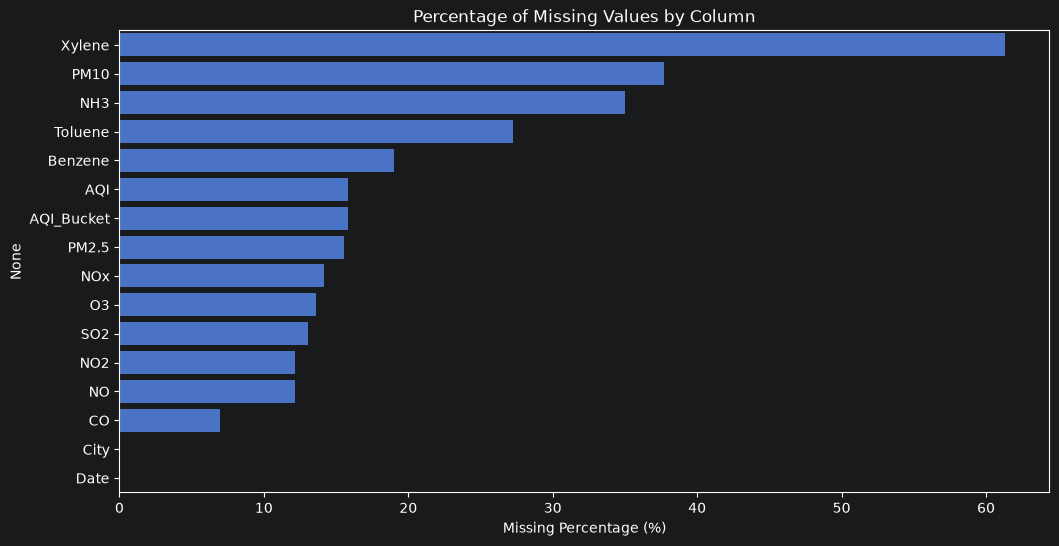

In [19]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=missing_summary["Missing Percentage"],
    y=missing_summary.index
)

plt.title("Percentage of Missing Values by Column")
plt.xlabel("Missing Percentage (%)")
plt.show()

In [20]:
city_aqi_summary = df.groupby("City")["AQI"].agg(
    total_observations="size",
    available_aqi="count"
)

city_aqi_summary["missing_aqi"] = (
    city_aqi_summary["total_observations"]
    - city_aqi_summary["available_aqi"]
)

city_aqi_summary["missing_percentage"] = (
    city_aqi_summary["missing_aqi"]
    / city_aqi_summary["total_observations"]
    * 100
)

city_aqi_summary.sort_values("missing_percentage")

,total_observations,available_aqi,missing_aqi,missing_percentage
City,,,,
Delhi,2009,1999,10,0.497760
Guwahati,502,495,7,1.394422
Chandigarh,304,299,5,1.644737
Aizawl,113,111,2,1.769912
Jaipur,1114,1094,20,1.795332
Kochi,162,158,4,2.469136
Bhopal,289,278,11,3.806228
Bengaluru,2009,1910,99,4.927825
Thiruvananthapuram,1112,1052,60,5.395683


## 11. Checking Time-Series Continuity

Before selecting the final forecasting series, we need to verify whether the observations for Delhi are recorded at regular daily intervals. A time-series model assumes that the temporal structure of the observations is meaningful, so identifying missing dates and gaps is an important part of data understanding.

In [21]:
delhi = df[df["City"] == "Delhi"].copy()

delhi["Date"] = pd.to_datetime(delhi["Date"])

delhi = delhi.sort_values("Date")

print("Number of observations:", len(delhi))
print("Start date:", delhi["Date"].min())
print("End date:", delhi["Date"].max())

Number of observations: 2009
Start date: 2015-01-01 00:00:00
End date: 2020-07-01 00:00:00


## 11. Checking Time-Series Continuity

Before selecting the final forecasting series, we need to verify whether the observations for Delhi are recorded at regular daily intervals. A time-series model assumes that the temporal structure of the observations is meaningful, so identifying missing dates and gaps is an important part of data understanding.

In [22]:
delhi = df[df["City"] == "Delhi"].copy()

delhi["Date"] = pd.to_datetime(delhi["Date"])

delhi = delhi.sort_values("Date")

print("Number of observations:", len(delhi))
print("Start date:", delhi["Date"].min())
print("End date:", delhi["Date"].max())

Number of observations: 2009
Start date: 2015-01-01 00:00:00
End date: 2020-07-01 00:00:00


In [23]:
date_diff = delhi["Date"].diff().dt.days

print("Maximum gap between observations:", date_diff.max(), "days")
print("Number of gaps greater than 1 day:", (date_diff > 1).sum())

Maximum gap between observations: 1.0 days
Number of gaps greater than 1 day: 0


In [24]:
gaps = delhi.loc[
    date_diff > 1,
    ["Date"]
].copy()

gaps["Previous_Date"] = delhi["Date"].shift(1)[date_diff > 1].values
gaps["Gap_Days"] = (
    gaps["Date"] - gaps["Previous_Date"]
).dt.days

gaps

,Date,Previous_Date,Gap_Days


## 12. Missing AQI Observations for Delhi

After identifying Delhi as the strongest candidate based on AQI availability, we will inspect the exact dates where AQI is missing. This will help us determine how these missing target observations should be handled during preprocessing.

In [25]:
delhi[delhi["AQI"].isna()][["Date", "AQI"]]

,Date,AQI
10799,2016-07-24,NaN
11133,2017-06-23,NaN
11184,2017-08-13,NaN
11185,2017-08-14,NaN
11193,2017-08-22,NaN
11194,2017-08-23,NaN
11197,2017-08-26,NaN
11198,2017-08-27,NaN
11199,2017-08-28,NaN
11200,2017-08-29,NaN


In [26]:
print("Missing AQI observations in Delhi:", delhi["AQI"].isna().sum())

Missing AQI observations in Delhi: 10


In [27]:
print("Maximum gap:", date_diff.max())
print("Gaps > 1 day:", (date_diff > 1).sum())

Maximum gap: 1.0
Gaps > 1 day: 0


In [28]:
gaps

,Date,Previous_Date,Gap_Days


In [29]:
delhi[delhi["AQI"].isna()][["Date", "AQI"]]

,Date,AQI
10799,2016-07-24,NaN
11133,2017-06-23,NaN
11184,2017-08-13,NaN
11185,2017-08-14,NaN
11193,2017-08-22,NaN
11194,2017-08-23,NaN
11197,2017-08-26,NaN
11198,2017-08-27,NaN
11199,2017-08-28,NaN
11200,2017-08-29,NaN


## 13. Final Selection of Forecasting Series

Based on the data-quality analysis, **Delhi** is selected as the initial forecasting location. Delhi contains **2,009 daily observations** covering the period from **2015-01-01 to 2020-07-01**, with only **10 missing AQI observations (approximately 0.5%)**. More importantly, the observations are recorded at regular daily intervals with **no gaps greater than one day**. This makes Delhi a suitable and reliable time series for developing our initial AQI forecasting models.

## 14. Summary of Data Understanding

The initial data exploration has provided us with the following understanding of the forecasting dataset.

In [30]:
summary = {
    "Total Rows": len(df),
    "Total Columns": df.shape[1],
    "Number of Cities": df["City"].nunique(),
    "Overall Missing AQI": df["AQI"].isna().sum(),
    "Selected City": "Delhi",
    "Delhi Observations": len(delhi),
    "Delhi Missing AQI": delhi["AQI"].isna().sum(),
    "Delhi Start Date": delhi["Date"].min(),
    "Delhi End Date": delhi["Date"].max(),
    "Delhi Maximum Date Gap": date_diff.max()
}

pd.Series(summary)

Total Rows                              29531
Total Columns                              16
Number of Cities                           26
Overall Missing AQI                      4681
Selected City                           Delhi
Delhi Observations                       2009
Delhi Missing AQI                          10
Delhi Start Date          2015-01-01 00:00:00
Delhi End Date            2020-07-01 00:00:00
Delhi Maximum Date Gap                    1.0
dtype: object

## ✅ Conclusion

The data understanding phase is now complete. We have identified **Delhi daily AQI** as our forecasting series because it provides a long, continuous, and highly complete time series. We also identified substantial missing values in several pollutant variables and a small number of missing AQI observations in Delhi. These findings will guide our preprocessing decisions in the next stage. We will now move to **data cleaning and preprocessing**, where we will prepare the Delhi AQI series for time-series analysis and forecasting.